# Phân Tích Dữ Liệu Dự Án Steam Với 8 Dạng Biểu Đồ
Notebook này chứa mã nguồn để trực quan hóa dữ liệu từ file `steam.csv` bằng 8 loại biểu đồ khác nhau, biểu diễn cho 8 thông tin/chỉ số quan trọng trong tập dữ liệu.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

try:
    df = pd.read_csv('steam.csv')
    print(f"Tải dữ liệu thành công! Kích thước dữ liệu: {df.shape}")
except FileNotFoundError:
    print("Không tìm thấy file 'steam.csv'. Vui lòng đặt file dữ liệu cùng thư mục với notebook này.")

Tải dữ liệu thành công! Kích thước dữ liệu: (27075, 18)


### 1. Biểu đồ cột (Bar Chart) - Top 10 Thể Loại Game Phổ Biến Nhất
Biểu thị tần suất xuất hiện của các thể loại chính nhằm xác định xu hướng sản xuất game trên nền tảng.

C:\Users\QUYNH HUONG\AppData\Local\Temp\ipykernel_1676\1625172483.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.values, y=top_genres.index, palette="viridis")


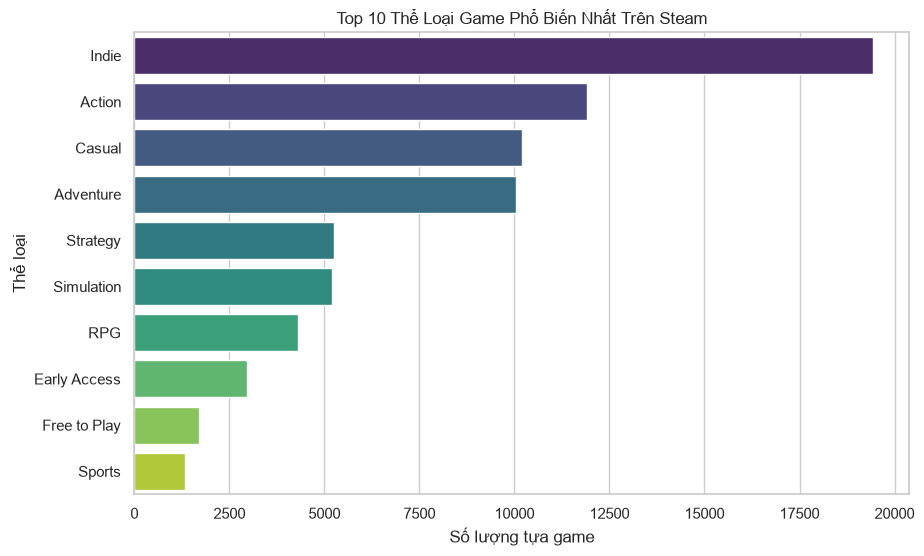

In [4]:
if 'genres' in df.columns:
    top_genres = df['genres'].str.split(';').explode().value_counts().head(10)
    
    sns.barplot(x=top_genres.values, y=top_genres.index, palette="viridis")
    plt.title("Top 10 Thể Loại Game Phổ Biến Nhất Trên Steam")
    plt.xlabel("Số lượng tựa game")
    plt.ylabel("Thể loại")
    plt.show()

### 2. Biểu đồ tròn (Pie Chart) - Tỷ Lệ Hỗ Trợ Tiếng Anh
Trực quan hóa tỷ lệ phần trăm giữa các tựa game có hỗ trợ ngôn ngữ tiếng Anh so với các ngôn ngữ khác.

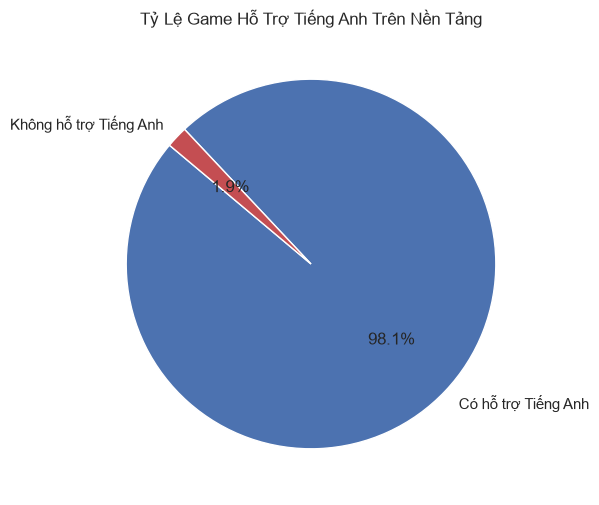

In [5]:
if 'english' in df.columns:
    english_counts = df['english'].value_counts()
    labels = ['Có hỗ trợ Tiếng Anh', 'Không hỗ trợ Tiếng Anh']
    
    plt.pie(english_counts, labels=labels, autopct='%1.1f%%', startangle=140, colors=['#4c72b0', '#c44e52'])
    plt.title("Tỷ Lệ Game Hỗ Trợ Tiếng Anh Trên Nền Tảng")
    plt.show()

### 3. Biểu đồ phân phối (Histogram) - Phân Phối Giá Bán Của Game
Xem xét mức giá phổ biến của các tựa game trên Steam (giới hạn dưới $50 để loại bỏ các điểm dị biệt quá cao).

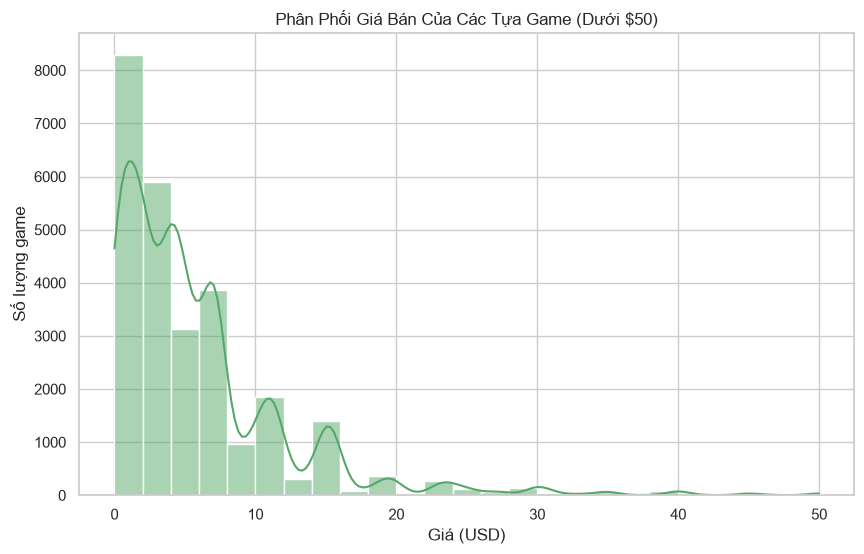

In [6]:
if 'price' in df.columns:
    filtered_price = df[df['price'] <= 50]['price']
    
    sns.histplot(filtered_price, bins=25, kde=True, color="#55a868")
    plt.title("Phân Phối Giá Bán Của Các Tựa Game (Dưới $50)")
    plt.xlabel("Giá (USD)")
    plt.ylabel("Số lượng game")
    plt.show()

### 4. Biểu đồ phân tán (Scatter Plot) - Mối Quan Hệ Giữa Đánh Giá Tích Cực & Tiêu Cực
Tìm hiểu mối tương quan giữa số lượng đánh giá tích cực (Positive Ratings) và tiêu cực (Negative Ratings).

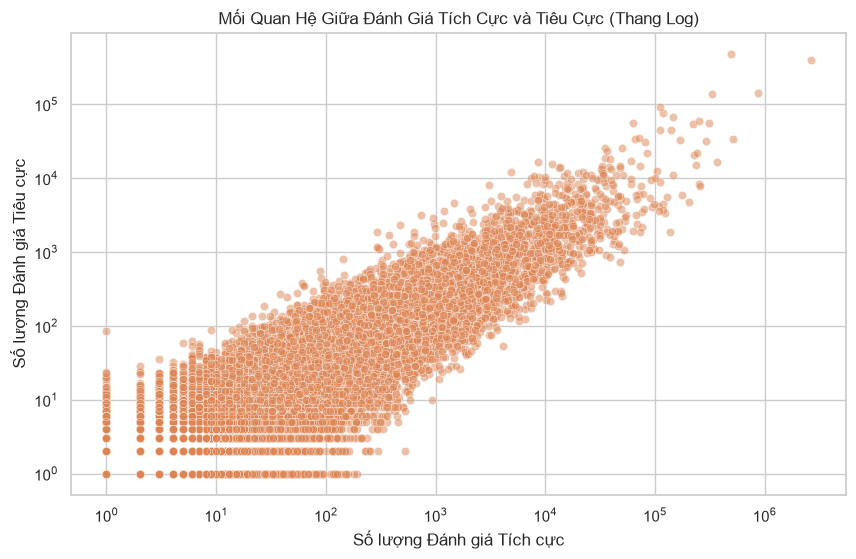

In [7]:
if 'positive_ratings' in df.columns and 'negative_ratings' in df.columns:
    sns.scatterplot(data=df, x='positive_ratings', y='negative_ratings', alpha=0.5, color="#dd8452")
    plt.xscale('log')
    plt.yscale('log')
    plt.title("Mối Quan Hệ Giữa Đánh Giá Tích Cực và Tiêu Cực (Thang Log)")
    plt.xlabel("Số lượng Đánh giá Tích cực")
    plt.ylabel("Số lượng Đánh giá Tiêu cực")
    plt.show()

### 5. Biểu đồ đường (Line Plot) - Xu Hướng Phát Hành Game Theo Năm
Theo dõi tốc độ tăng trưởng và số lượng trò chơi được phát hành qua các năm trên hệ thống Steam.

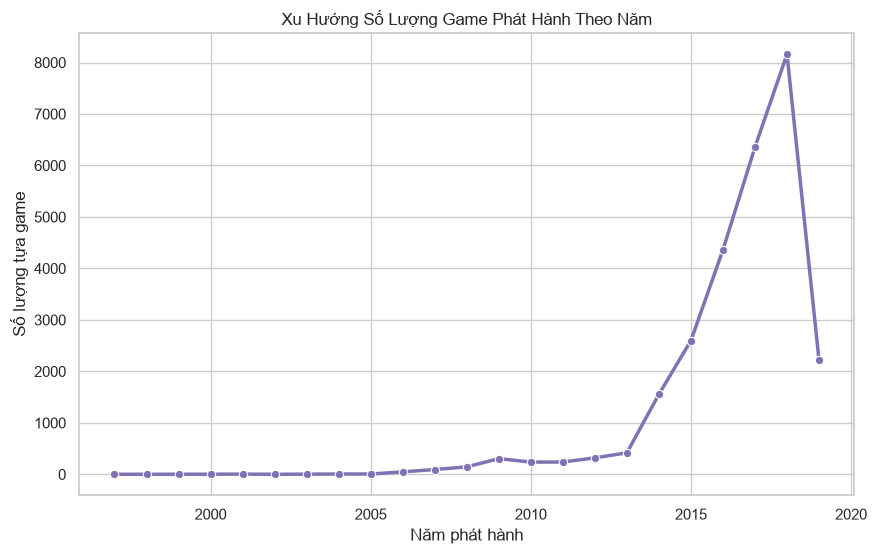

In [8]:
if 'release_date' in df.columns:
    df['release_year'] = pd.to_datetime(df['release_date']).dt.year
    yearly_releases = df['release_year'].value_counts().sort_index()
    yearly_releases = yearly_releases[yearly_releases.index < 2020]
    
    sns.lineplot(x=yearly_releases.index, y=yearly_releases.values, marker="o", color="#8172b3", linewidth=2.5)
    plt.title("Xu Hướng Số Lượng Game Phát Hành Theo Năm")
    plt.xlabel("Năm phát hành")
    plt.ylabel("Số lượng tựa game")
    plt.show()

### 6. Biểu đồ nhiệt (Heatmap) - Ma Trận Tương Quan Biến Số
Đo lường mức độ ảnh hưởng lẫn nhau giữa các chỉ số định lượng (Giá, Đánh giá, Thành tựu, Thời gian chơi).

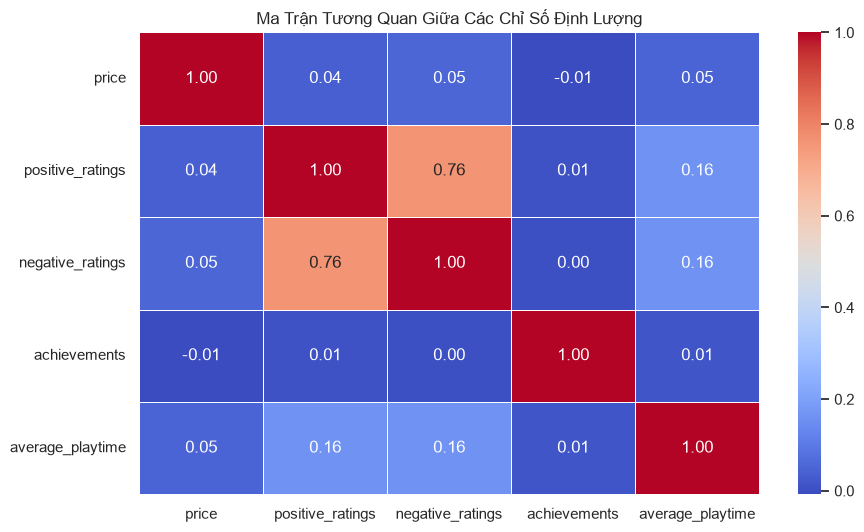

In [9]:
numerical_cols = ['price', 'positive_ratings', 'negative_ratings', 'achievements', 'average_playtime']
available_cols = [col for col in numerical_cols if col in df.columns]

if available_cols:
    corr_matrix = df[available_cols].corr()
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5)
    plt.title("Ma Trận Tương Quan Giữa Các Chỉ Số Định Lượng")
    plt.show()

### 7. Biểu đồ hộp (Box Plot) - Phân Phối Thời Gian Chơi Theo Thể Loại
Khảo sát thời gian chơi trung bình của người dùng đối với một số thể loại game phổ biến hàng đầu.

C:\Users\QUYNH HUONG\AppData\Local\Temp\ipykernel_1676\2010266202.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=filtered_df, x='main_genre', y='average_playtime', palette="pastel")


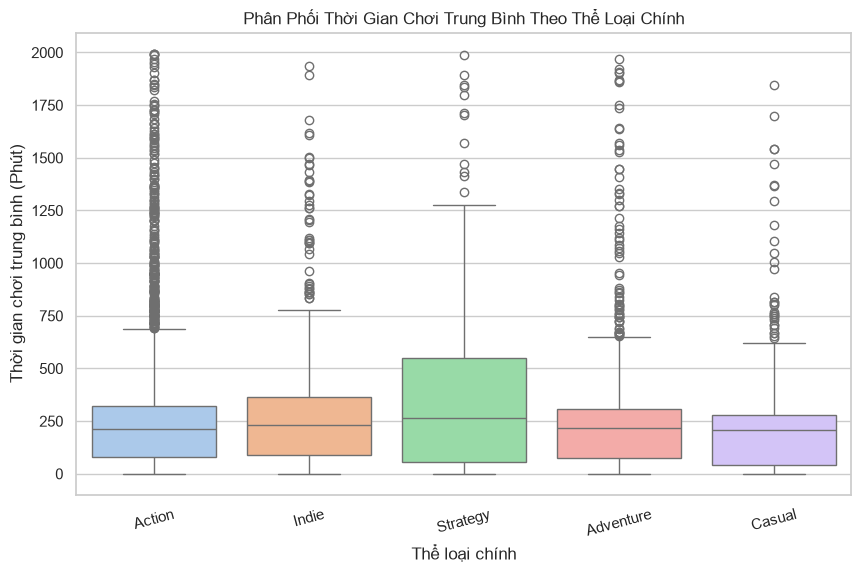

In [10]:
if 'average_playtime' in df.columns and 'genres' in df.columns:
    active_games = df[(df['average_playtime'] > 0) & (df['average_playtime'] < 2000)].copy()
    active_games['main_genre'] = active_games['genres'].apply(lambda x: x.split(';')[0])
    top_5_genres = active_games['main_genre'].value_counts().head(5).index
    filtered_df = active_games[active_games['main_genre'].isin(top_5_genres)]
    
    sns.boxplot(data=filtered_df, x='main_genre', y='average_playtime', palette="pastel")
    plt.title("Phân Phối Thời Gian Chơi Trung Bình Theo Thể Loại Chính")
    plt.xlabel("Thể loại chính")
    plt.ylabel("Thời gian chơi trung bình (Phút)")
    plt.xticks(rotation=15)
    plt.show()

### 8. Biểu đồ vĩ cầm (Violin Plot) - Biến Động Giá Theo Phân Loại Bản Quyền
Kết hợp giữa biểu đồ hộp và biểu đồ mật độ hạt để xem cấu trúc phân phối giá tiền của các game thuộc nhóm Độc lập (Indie) và Phổ thông.

C:\Users\QUYNH HUONG\AppData\Local\Temp\ipykernel_1676\575593818.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=price_df, x='is_indie', y='price', palette="muted", inner="quartile")


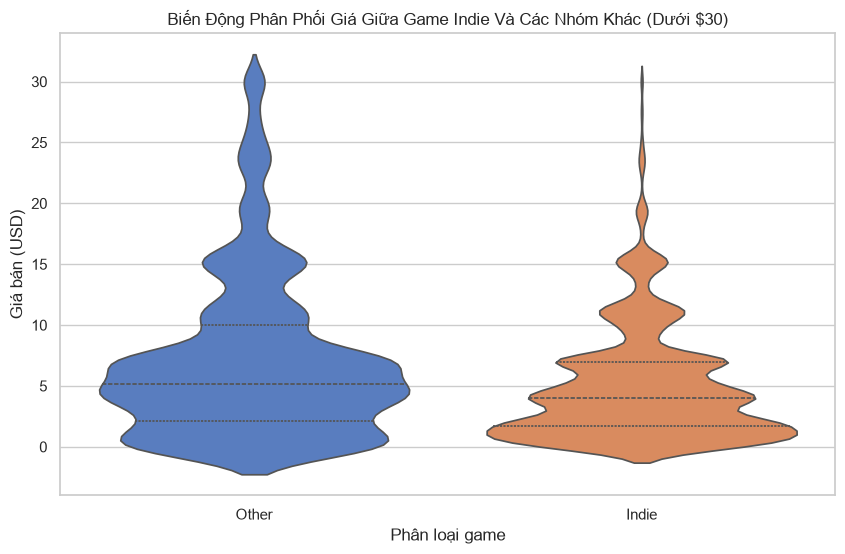

In [11]:
if 'price' in df.columns and 'genres' in df.columns:
    df['is_indie'] = df['genres'].apply(lambda x: 'Indie' if 'Indie' in x else 'Other')
    price_df = df[df['price'] <= 30]
    
    sns.violinplot(data=price_df, x='is_indie', y='price', palette="muted", inner="quartile")
    plt.title("Biến Động Phân Phối Giá Giữa Game Indie Và Các Nhóm Khác (Dưới $30)")
    plt.xlabel("Phân loại game")
    plt.ylabel("Giá bán (USD)")
    plt.show()